In [ ]:
import  pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier ,plot_tree
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
data = {
    'Study_Hours': [
        2, 5, 1, 6, 3, 7, 4, 8, 2, 5,
        6, 1, 9, 3, 7, 4, 2, 8, 5, 6,
        3, 9, 1, 7, 4, 8, 2, 6, 5, 3
    ],

    'Attendance': [
        55, 80, 40, 85, 65, 90, 75, 95, 50, 82,
        88, 45, 98, 60, 92, 70, 58, 96, 78, 85,
        62, 99, 35, 91, 72, 94, 52, 87, 81, 64
    ],

    'Previous_Marks': [
        35, 65, 25, 75, 45, 85, 55, 90, 30, 68,
        78, 20, 95, 40, 88, 50, 32, 92, 62, 80,
        42, 98, 18, 86, 58, 94, 28, 76, 70, 44
    ],

    'Result': [
        'Fail', 'Pass', 'Fail', 'Pass', 'Fail',
        'Pass', 'Pass', 'Pass', 'Fail', 'Pass',
        'Pass', 'Fail', 'Pass', 'Fail', 'Pass',
        'Pass', 'Fail', 'Pass', 'Pass', 'Pass',
        'Fail', 'Pass', 'Fail', 'Pass', 'Pass',
        'Pass', 'Fail', 'Pass', 'Pass', 'Fail'
    ]
}

df = pd.DataFrame(data)
display(df.head())

,Study_Hours,Attendance,Previous_Marks,Result
0,2,55,35,Fail
1,5,80,65,Pass
2,1,40,25,Fail
3,6,85,75,Pass
4,3,65,45,Fail


In [ ]:
x = df[['Study_Hours','Attendance','Previous_Marks']]
y = df['Result']

print("Input features: ")
display(x.head())

print("Target variable: ")
display(y.head())

Input features: 


,Study_Hours,Attendance,Previous_Marks
0,2,55,35
1,5,80,65
2,1,40,25
3,6,85,75
4,3,65,45


Target variable: 


,Result
0,Fail
1,Pass
2,Fail
3,Pass
4,Fail


In [ ]:
x_tr, x_te, y_tr, y_te = train_test_split(
    x,y,
    test_size=0.2,
    random_state=42,
    stratify=y
    )

print("Training records:",len(x_tr))
print("Testing records:",len(x_te))

Training records: 24
Testing records: 6


In [ ]:
tree_clf= DecisionTreeClassifier(max_depth=4,random_state=42)
tree_clf.fit(x_tr,y_tr)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [ ]:
y_pred = tree_clf.predict(x_te)

comparison = pd.DataFrame({
    'Actual': y_te.values,
    'Predicted': y_pred
})

display(comparison)

,Actual,Predicted
0,Fail,Fail
1,Pass,Pass
2,Pass,Pass
3,Pass,Pass
4,Pass,Pass
5,Fail,Fail


In [ ]:
print("Accuracy : ", round(accuracy_score(y_te , y_pred), 3))
print("\n Classification Report: ")
print(classification_report(y_te,y_pred,zero_division=0))

Accuracy :  1.0

 Classification Report: 
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         2
        Pass       1.00      1.00      1.00         4

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



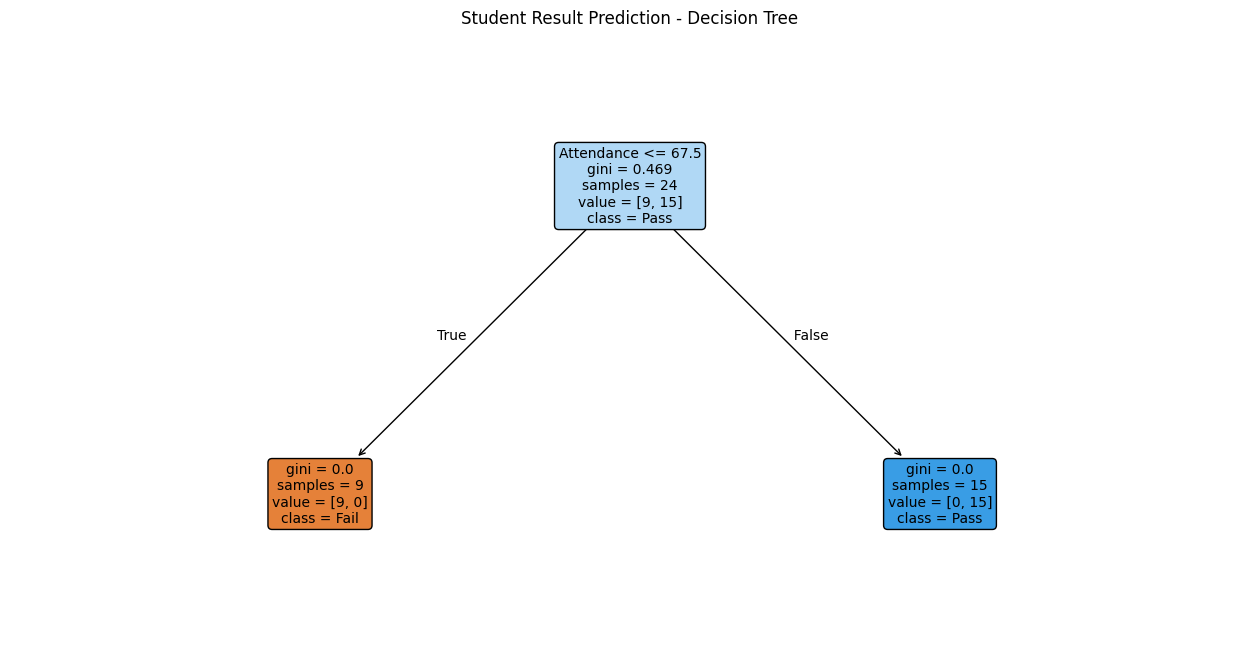

In [ ]:
plt.figure(figsize=(16, 8))

plot_tree(
    tree_clf,
    feature_names=x.columns,
    class_names=[str(c) for c in tree_clf.classes_],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Student Result Prediction - Decision Tree")
plt.show()